In [1]:
import os, numpy as np, tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow import keras
from tensorflow.keras.applications import DenseNet121, ResNet50, VGG16, EfficientNetB0
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras import Model
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

2026-03-05 10:53:04.643439: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-05 10:53:05.090172: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-03-05 10:53:07.227080: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPUs detectadas:", tf.config.list_physical_devices('GPU'))

build_info = tf.sysconfig.get_build_info()
print("\nClaves disponibles en get_build_info():")
print(build_info.keys())

print("\nInformación del entorno:")
for k, v in build_info.items():
    print(f"{k}: {v}")

TensorFlow: 2.20.0
GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Claves disponibles en get_build_info():
odict_keys(['cpu_compiler', 'cuda_compute_capabilities', 'cuda_version', 'cudnn_version', 'is_cuda_build', 'is_rocm_build', 'is_tensorrt_build'])

Información del entorno:
cpu_compiler: clang 18
cuda_compute_capabilities: ['sm_60', 'sm_70', 'sm_80', 'sm_89', 'compute_90']
cuda_version: 12.5.1
cudnn_version: 9
is_cuda_build: True
is_rocm_build: False
is_tensorrt_build: False


In [3]:
# 🔧 Configurar GPU para asignar memoria de forma dinámica
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("✅ Memoria de GPU configurada para crecimiento dinámico.")
    except RuntimeError as e:
        print("❌ Error al configurar memoria de GPU:", e)

✅ Memoria de GPU configurada para crecimiento dinámico.


In [4]:
# =========================
directory= "/home/karla/.cache/kagglehub/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/versions/1/lung_colon_image_set/lung_image_sets"
generator=tf.keras.preprocessing.image.ImageDataGenerator(
        rotation_range=5,
        width_shift_range=0.05,
        height_shift_range=0.05,
        shear_range=0.05,
        zoom_range=0.05,
        horizontal_flip=True,
        vertical_flip=True,
        validation_split=0.15,
        fill_mode='nearest')
training_generator=generator.flow_from_directory(
    directory,
    target_size=(224, 224),
    class_mode='categorical',
    batch_size=32,
    shuffle=True,
    subset='training',
    seed=30,
)

val_generator=generator.flow_from_directory(
    directory,
    target_size=(224, 224),
    class_mode='categorical',
    batch_size=32,
    shuffle=False,
    subset='validation',
    seed=30,
)

Found 12750 images belonging to 3 classes.
Found 2250 images belonging to 3 classes.


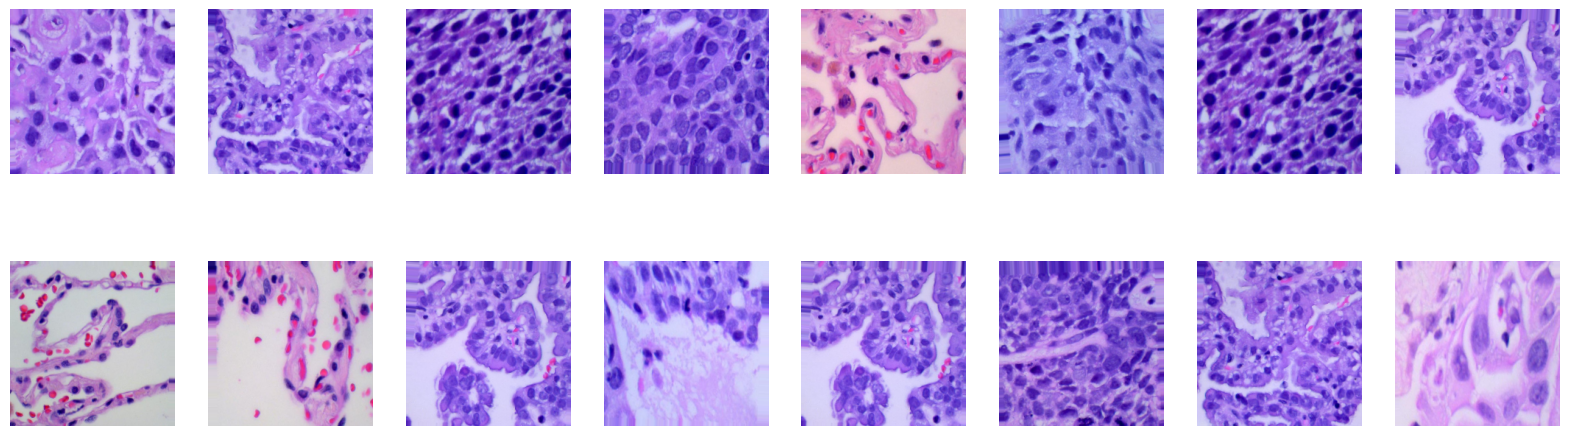

In [5]:
x,y=next(training_generator)

from random import seed, randint

plt.figure(1, figsize=(20,6))
plt.tight_layout()
for i in range(8):
    j = randint(0, x.shape[0]-1)
    plt.subplot(2, 8, i+1)

    plt.imshow(x[j,:,:,:].astype(np.uint8), cmap='gray')
    plt.axis("off")
    j = randint(0, x.shape[0]-1)
    plt.subplot(2, 8, i+9)

    plt.imshow(x[j,:,:,:].astype(np.uint8), cmap='gray')
    plt.axis("off")
plt.show()

# MODELO 1: DenseNet121

In [6]:
base_model = DenseNet121(
    weights='imagenet',  # Load weights pre-trained on ImageNet.
    input_shape=(224, 224, 3),
    include_top=False, 
    pooling = "avg")

base_model.trainable = False

xi=tf.keras.layers.Input(shape=(224, 224, 3),dtype=tf.uint8)
x = densenet_preprocess(xi)
x = base_model(x)
x = keras.layers.Flatten()(x)
x = keras.layers.Dropout(0.2)(x)  # Regularize with dropout
x = keras.layers.Dense(256, activation='relu')(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.Dense(64, activation='relu')(x)
x = keras.layers.BatchNormalization()(x)
xoutputs = keras.layers.Dense(3, activation='softmax')(x)

model_densenet = Model(inputs=[xi],outputs=[xoutputs])
print("=== DenseNet121 ===")
print(model_densenet.summary())

I0000 00:00:1772733231.811222   58498 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3539 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


=== DenseNet121 ===


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add (Add)                       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 1024)           │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,317,827 (27.92 MB)

 Trainable params: 279,683 (1.07 MB)

 Non-trainable params: 7,038,144 (26.85 MB)

None


In [7]:
model_densenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy'] )

print("\n⏳ Entrenando DenseNet121...")
history_densenet = model_densenet.fit(
    x=training_generator,
    batch_size=32,
    epochs=5,
    verbose=1,
    validation_data=val_generator,
    shuffle=True,
)


⏳ Entrenando DenseNet121...
Epoch 1/5


2026-03-05 10:54:09.312795: I external/local_xla/xla/service/service.cc:163] XLA service 0x7e95040030c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-03-05 10:54:09.312849: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9
2026-03-05 10:54:09.763423: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-03-05 10:54:12.893628: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91900
2026-03-05 10:54:13.382220: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-03-05 10:54:13.

399/399 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step - accuracy: 0.7291 - loss: 0.6292

2026-03-05 10:58:26.557726: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng54{k2=1,k12=-1,k13=0,k14=3,k15=0,k17=96,k18=0,k23=0} for conv (f32[10,128,28,28]{3,2,1,0}, u8[0]{0}) custom-call(f32[10,288,28,28]{3,2,1,0}, f32[128,288,1,1]{3,2,1,0}), window={size=1x1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-03-05 10:58:26.560272: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.630725781s
Trying algorithm eng54{k2=1,k12=-1,k13=0,k14=3,k15=0,k17=96,k18=0,k23=0} for conv (f32[10,128,28,28]{3,2,1,0}, u8[0]{0}) custom-call(f32[10,288,28,28]{3,2,1,0}, f32[128,288,1,1]{3,2,1,0}), window={size=1x1}, dim_labels=bf01_oi01->bf01, custom_ca

399/399 ━━━━━━━━━━━━━━━━━━━━ 288s 574ms/step - accuracy: 0.8427 - loss: 0.3838 - val_accuracy: 0.9427 - val_loss: 0.1388
Epoch 2/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 140s 350ms/step - accuracy: 0.9265 - loss: 0.1906 - val_accuracy: 0.9573 - val_loss: 0.1060
Epoch 3/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 137s 342ms/step - accuracy: 0.9345 - loss: 0.1649 - val_accuracy: 0.9631 - val_loss: 0.0988
Epoch 4/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 131s 328ms/step - accuracy: 0.9438 - loss: 0.1446 - val_accuracy: 0.9618 - val_loss: 0.0906
Epoch 5/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 165s 412ms/step - accuracy: 0.9473 - loss: 0.1320 - val_accuracy: 0.9640 - val_loss: 0.0903


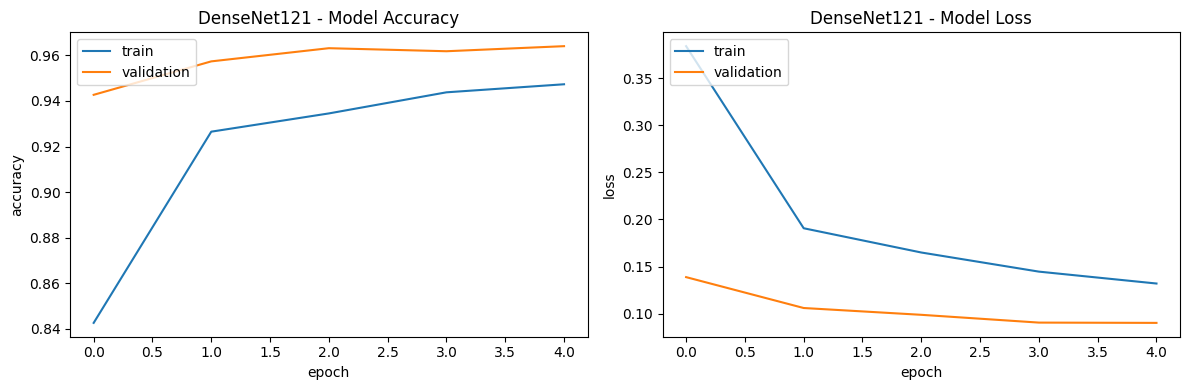

In [8]:
#  "Accuracy"
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_densenet.history['accuracy'])
plt.plot(history_densenet.history['val_accuracy'])
plt.title('DenseNet121 - Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')

# "Loss"
plt.subplot(1, 2, 2)
plt.plot(history_densenet.history['loss'])
plt.plot(history_densenet.history['val_loss'])
plt.title('DenseNet121 - Model Loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.tight_layout()
plt.show()


EVALUACIÓN: DenseNet121


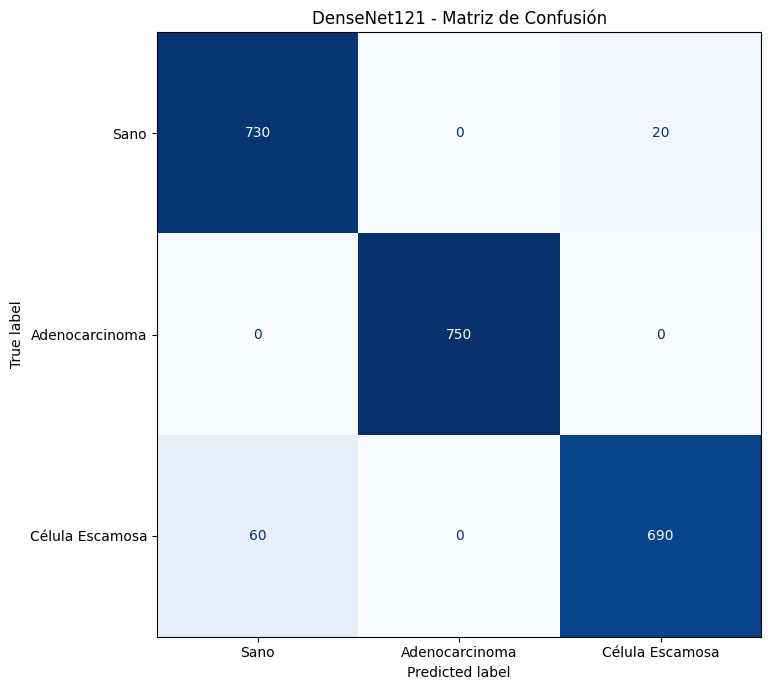


Reporte de clasificación (DenseNet121):
                 precision    recall  f1-score   support

           Sano     0.9241    0.9733    0.9481       750
 Adenocarcinoma     1.0000    1.0000    1.0000       750
Célula Escamosa     0.9718    0.9200    0.9452       750

       accuracy                         0.9644      2250
      macro avg     0.9653    0.9644    0.9644      2250
   weighted avg     0.9653    0.9644    0.9644      2250


✓ Exactitud en validación: 96.44%


In [9]:
#%% Matriz de confusión y reporte de clasificación - DenseNet121
print("\n" + "="*50)
print("EVALUACIÓN: DenseNet121")
print("="*50)

# Predicciones en TODO el conjunto de validación
y_pred_probs = model_densenet.predict(val_generator, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = val_generator.labels

# Matriz de confusión (cuentas)
cm_densenet = confusion_matrix(y_true, y_pred, labels=np.arange(3))

# Visualizar
disp = ConfusionMatrixDisplay(confusion_matrix=cm_densenet, display_labels=["Sano", "Adenocarcinoma", "Célula Escamosa"])
fig, ax = plt.subplots(figsize=(8, 7))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("DenseNet121 - Matriz de Confusión")
plt.tight_layout()
plt.show()

# Reporte de clasificación
print("\nReporte de clasificación (DenseNet121):")
print(classification_report(y_true, y_pred, target_names=["Sano", "Adenocarcinoma", "Célula Escamosa"], digits=4))

# Calcular exactitud
acc_densenet = np.sum(y_pred == y_true) / len(y_true)
print(f"\n✓ Exactitud en validación: {acc_densenet*100:.2f}%")

# MODELO 2: ResNet50

In [10]:
# ===========================
# MODELO 2: ResNet50
# ===========================
print("\n" + "="*60)  
print("MODELO 2: ResNet50")
print("="*60)

base_model_resnet = ResNet50(
    weights='imagenet',
    input_shape=(224, 224, 3),
    include_top=False,
    pooling="avg")

base_model_resnet.trainable = False

xi_resnet = tf.keras.layers.Input(shape=(224, 224, 3), dtype=tf.uint8)
x = resnet_preprocess(xi_resnet)
x = base_model_resnet(x)
x = keras.layers.Flatten()(x)
x = keras.layers.Dropout(0.2)(x)
x = keras.layers.Dense(256, activation='relu')(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.Dense(64, activation='relu')(x)
x = keras.layers.BatchNormalization()(x)
x_outputs = keras.layers.Dense(3, activation='softmax')(x)

model_resnet = Model(inputs=[xi_resnet], outputs=[x_outputs])
print("\n=== ResNet50 ===")
print(model_resnet.summary())

# Compilar y entrenar
model_resnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy'])

print("\n⏳ Entrenando ResNet50...")
history_resnet = model_resnet.fit(
    x=training_generator,
    batch_size=32,
    epochs=5,
    verbose=1,
    validation_data=val_generator,
    shuffle=True,
)


MODELO 2: ResNet50

=== ResNet50 ===


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_3[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 2048)      │ 23,587,712 │ add_1[0][0]       │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 2048)      │          0 │ resnet50[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 2048)      │          0 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 256)       │    524,544 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │     16,448 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_4[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 3)         │        195 │ batch_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,130,179 (92.05 MB)

 Trainable params: 541,827 (2.07 MB)

 Non-trainable params: 23,588,352 (89.98 MB)

None

⏳ Entrenando ResNet50...
Epoch 1/5


2026-03-05 11:09:17.711795: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-03-05 11:09:18.815009: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4149', 56 bytes spill stores, 56 bytes spill loads

2026-03-05 11:09:19.193137: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6129', 520 bytes spill stores, 520 bytes spill loads



399/399 ━━━━━━━━━━━━━━━━━━━━ 0s 328ms/step - accuracy: 0.7901 - loss: 0.5056

2026-03-05 11:11:43.763051: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1790', 20 bytes spill stores, 20 bytes spill loads

2026-03-05 11:12:08.962381: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng13{} for conv (f32[10,512,7,7]{3,2,1,0}, u8[0]{0}) custom-call(f32[10,512,7,7]{3,2,1,0}, f32[512,512,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-03-05 11:12:09.012430: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 2.427732267s
Trying algorithm e

399/399 ━━━━━━━━━━━━━━━━━━━━ 184s 404ms/step - accuracy: 0.8851 - loss: 0.2896 - val_accuracy: 0.9529 - val_loss: 0.1147
Epoch 2/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 125s 313ms/step - accuracy: 0.9430 - loss: 0.1464 - val_accuracy: 0.9738 - val_loss: 0.0745
Epoch 3/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 151s 378ms/step - accuracy: 0.9536 - loss: 0.1215 - val_accuracy: 0.9747 - val_loss: 0.0733
Epoch 4/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 121s 304ms/step - accuracy: 0.9613 - loss: 0.1018 - val_accuracy: 0.9836 - val_loss: 0.0539
Epoch 5/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 123s 308ms/step - accuracy: 0.9608 - loss: 0.1010 - val_accuracy: 0.9844 - val_loss: 0.0511


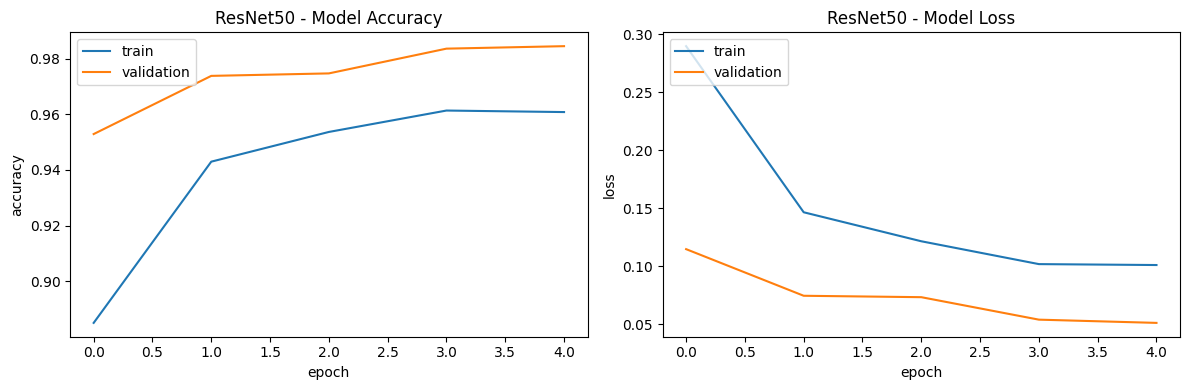


EVALUACIÓN: ResNet50


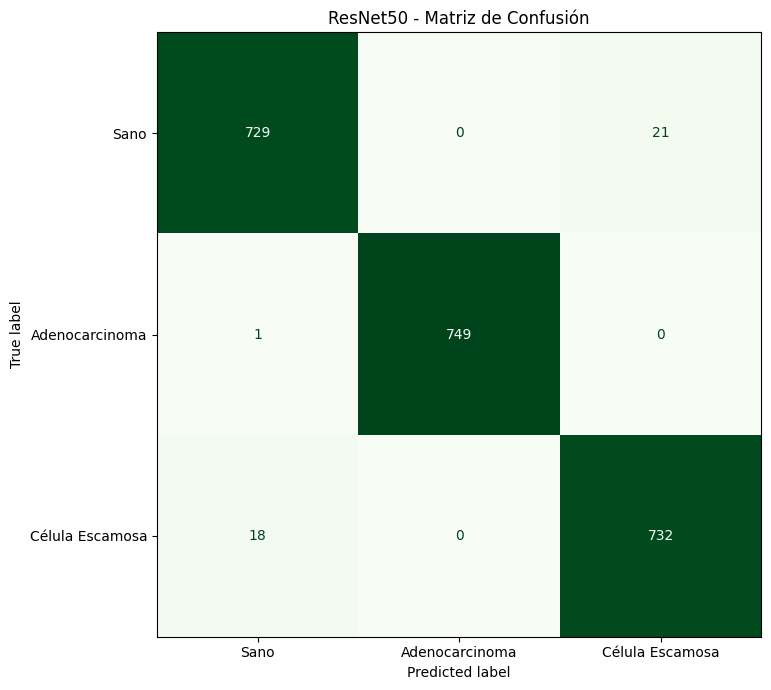


Reporte de clasificación (ResNet50):
                 precision    recall  f1-score   support

           Sano     0.9746    0.9720    0.9733       750
 Adenocarcinoma     1.0000    0.9987    0.9993       750
Célula Escamosa     0.9721    0.9760    0.9741       750

       accuracy                         0.9822      2250
      macro avg     0.9822    0.9822    0.9822      2250
   weighted avg     0.9822    0.9822    0.9822      2250


✓ Exactitud en validación: 98.22%


In [11]:
# Gráficos ResNet50
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_resnet.history['accuracy'])
plt.plot(history_resnet.history['val_accuracy'])
plt.title('ResNet50 - Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')

plt.subplot(1, 2, 2)
plt.plot(history_resnet.history['loss'])
plt.plot(history_resnet.history['val_loss'])
plt.title('ResNet50 - Model Loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.tight_layout()
plt.show()

# Evaluación ResNet50
print("\n" + "="*50)
print("EVALUACIÓN: ResNet50")
print("="*50)

y_pred_probs_resnet = model_resnet.predict(val_generator, verbose=0)
y_pred_resnet = np.argmax(y_pred_probs_resnet, axis=1)

cm_resnet = confusion_matrix(y_true, y_pred_resnet, labels=np.arange(3))

disp = ConfusionMatrixDisplay(confusion_matrix=cm_resnet, display_labels=["Sano", "Adenocarcinoma", "Célula Escamosa"])
fig, ax = plt.subplots(figsize=(8, 7))
disp.plot(ax=ax, cmap="Greens", values_format="d", colorbar=False)
plt.title("ResNet50 - Matriz de Confusión")
plt.tight_layout()
plt.show()

print("\nReporte de clasificación (ResNet50):")
print(classification_report(y_true, y_pred_resnet, target_names=["Sano", "Adenocarcinoma", "Célula Escamosa"], digits=4))

acc_resnet = np.sum(y_pred_resnet == y_true) / len(y_true)
print(f"\n✓ Exactitud en validación: {acc_resnet*100:.2f}%")

# MODELO 3: VGG16

In [12]:
# ===========================

# ===========================
print("\n" + "="*60)
print("MODELO 3: VGG16")
print("="*60)

base_model_vgg = VGG16(
    weights='imagenet',
    input_shape=(224, 224, 3),
    include_top=False,
    pooling="avg")

base_model_vgg.trainable = False

xi_vgg = tf.keras.layers.Input(shape=(224, 224, 3), dtype=tf.uint8)
x = vgg_preprocess(xi_vgg)
x = base_model_vgg(x)
x = keras.layers.Flatten()(x)
x = keras.layers.Dropout(0.2)(x)
x = keras.layers.Dense(256, activation='relu')(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.Dense(64, activation='relu')(x)
x = keras.layers.BatchNormalization()(x)
x_outputs = keras.layers.Dense(3, activation='softmax')(x)

model_vgg = Model(inputs=[xi_vgg], outputs=[x_outputs])
print("\n=== VGG16 ===")
print(model_vgg.summary())

# Compilar y entrenar
model_vgg.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy'])

print("\n⏳ Entrenando VGG16...")
history_vgg = model_vgg.fit(
    x=training_generator,
    batch_size=32,
    epochs=5,
    verbose=1,
    validation_data=val_generator,
    shuffle=True,
)


MODELO 3: VGG16

=== VGG16 ===


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 224, 224)  │          0 │ input_layer_5[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 224, 224)  │          0 │ input_layer_5[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 224, 224)  │          0 │ input_layer_5[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 224, 224,  │          0 │ get_item_3[0][0], │
│                     │ 3)                │            │ get_item_4[0][0], │
│                     │                   │            │ get_item_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 224, 224,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 512)       │ 14,714,688 │ add_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 512)       │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 512)       │          0 │ flatten_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 256)       │    131,328 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_6[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 64)        │     16,448 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_7[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 3)         │        195 │ batch_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,863,939 (56.70 MB)

 Trainable params: 148,611 (580.51 KB)

 Non-trainable params: 14,715,328 (56.13 MB)

... (3 outputs left out)

2026-03-05 11:24:20.026666: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.47GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


399/399 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step - accuracy: 0.6813 - loss: 0.7745

2026-03-05 11:25:56.618186: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng15{k5=1,k6=0,k7=1,k10=0} for conv (f32[10,128,112,112]{3,2,1,0}, u8[0]{0}) custom-call(f32[10,128,112,112]{3,2,1,0}, f32[128,128,3,3]{3,2,1,0}, f32[128]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kRelu","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-03-05 11:25:56.793241: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 2.465881479s
Trying algorithm eng15{k5=1,k6=0,k7=1,k10=0} for conv (f32[10,128,112,112]{3,2,1,0}, u8[0]{0}) custom-call(f32[10,128,112,112]{3,2,1,0}, f32[128,128,3,3]{3,2,1,0}, f32[128]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01-

399/399 ━━━━━━━━━━━━━━━━━━━━ 258s 540ms/step - accuracy: 0.8051 - loss: 0.4795 - val_accuracy: 0.9382 - val_loss: 0.1780
Epoch 2/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 182s 454ms/step - accuracy: 0.9075 - loss: 0.2469 - val_accuracy: 0.9551 - val_loss: 0.1325
Epoch 3/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 181s 453ms/step - accuracy: 0.9237 - loss: 0.2028 - val_accuracy: 0.9516 - val_loss: 0.1239
Epoch 4/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 185s 461ms/step - accuracy: 0.9287 - loss: 0.1862 - val_accuracy: 0.9587 - val_loss: 0.1089
Epoch 5/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 531s 1s/step - accuracy: 0.9328 - loss: 0.1780 - val_accuracy: 0.9613 - val_loss: 0.1071


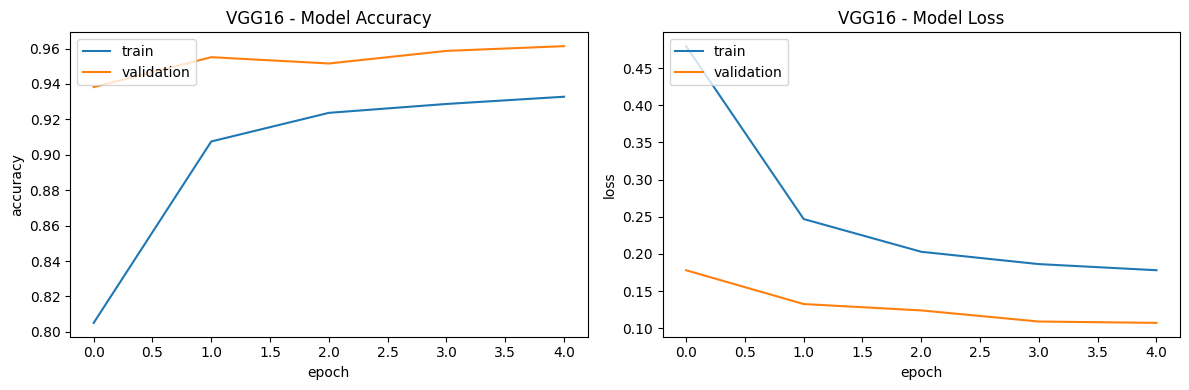


EVALUACIÓN: VGG16


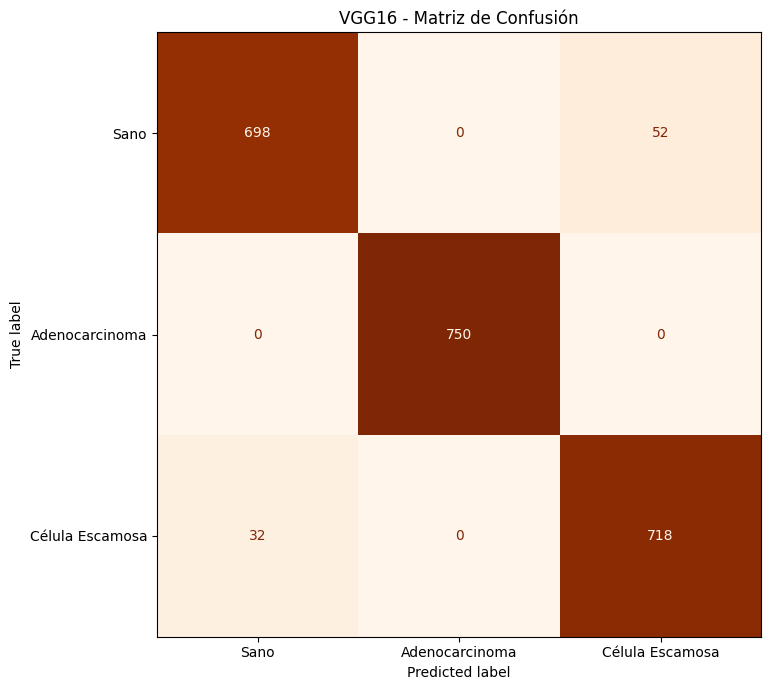


Reporte de clasificación (VGG16):
                 precision    recall  f1-score   support

           Sano     0.9562    0.9307    0.9432       750
 Adenocarcinoma     1.0000    1.0000    1.0000       750
Célula Escamosa     0.9325    0.9573    0.9447       750

       accuracy                         0.9627      2250
      macro avg     0.9629    0.9627    0.9627      2250
   weighted avg     0.9629    0.9627    0.9627      2250


✓ Exactitud en validación: 96.27%


In [13]:
# Gráficos VGG16
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_vgg.history['accuracy'])
plt.plot(history_vgg.history['val_accuracy'])
plt.title('VGG16 - Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')

plt.subplot(1, 2, 2)
plt.plot(history_vgg.history['loss'])
plt.plot(history_vgg.history['val_loss'])
plt.title('VGG16 - Model Loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.tight_layout()
plt.show()

# Evaluación VGG16
print("\n" + "="*50)
print("EVALUACIÓN: VGG16")
print("="*50)

y_pred_probs_vgg = model_vgg.predict(val_generator, verbose=0)
y_pred_vgg = np.argmax(y_pred_probs_vgg, axis=1)

cm_vgg = confusion_matrix(y_true, y_pred_vgg, labels=np.arange(3))

disp = ConfusionMatrixDisplay(confusion_matrix=cm_vgg, display_labels=["Sano", "Adenocarcinoma", "Célula Escamosa"])
fig, ax = plt.subplots(figsize=(8, 7))
disp.plot(ax=ax, cmap="Oranges", values_format="d", colorbar=False)
plt.title("VGG16 - Matriz de Confusión")
plt.tight_layout()
plt.show()

print("\nReporte de clasificación (VGG16):")
print(classification_report(y_true, y_pred_vgg, target_names=["Sano", "Adenocarcinoma", "Célula Escamosa"], digits=4))

acc_vgg = np.sum(y_pred_vgg == y_true) / len(y_true)
print(f"\n✓ Exactitud en validación: {acc_vgg*100:.2f}%")

# COMPARACIÓN DE MODELOS


COMPARACIÓN DE RESULTADOS

📊 EXACTITUD EN CONJUNTO DE VALIDACIÓN:
----------------------------------------
DenseNet121     |  96.44% | APROBADO
ResNet50        |  98.22% | APROBADO
VGG16           |  96.27% | APROBADO


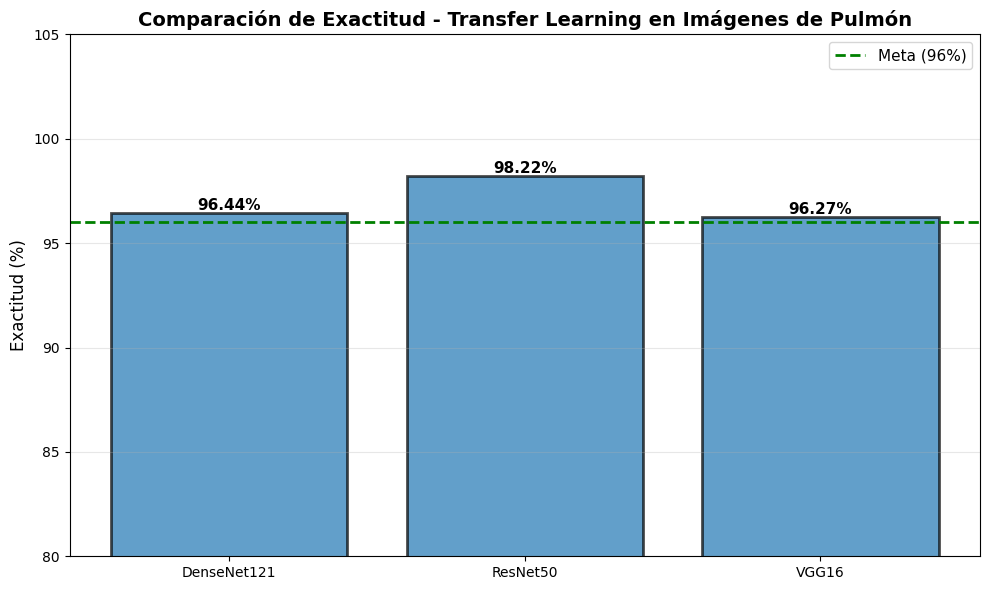


MODELO GANADOR: ResNet50
    Exactitud: 98.22%


In [14]:
# ===========================
# ===========================
print("\n" + "="*60)
print("COMPARACIÓN DE RESULTADOS")
print("="*60)

# Crear tabla comparativa
modelos = ["DenseNet121", "ResNet50", "VGG16"]
exactitudes = [acc_densenet*100, acc_resnet*100, acc_vgg*100]

print("\n📊 EXACTITUD EN CONJUNTO DE VALIDACIÓN:")
print("-" * 40)
for modelo, exactitud in zip(modelos, exactitudes):
    status = "APROBADO" if exactitud >= 96 else "NO APROBADO"
    print(f"{modelo:15} | {exactitud:6.2f}% | {status}")

# Visualizar comparación
plt.figure(figsize=(10, 6))
colors = ['#1f77b4' if acc >= 96 else '#d62728' for acc in exactitudes]
bars = plt.bar(modelos, exactitudes, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
plt.axhline(y=96, color='green', linestyle='--', linewidth=2, label='Meta (96%)')
plt.ylabel('Exactitud (%)', fontsize=12)
plt.title('Comparación de Exactitud - Transfer Learning en Imágenes de Pulmón', fontsize=14, fontweight='bold')
plt.ylim([80, 105])
plt.legend(fontsize=11)
plt.grid(axis='y', alpha=0.3)

# Agregar valores sobre las barras
for bar, acc in zip(bars, exactitudes):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{acc:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nMODELO GANADOR: " + modelos[np.argmax(exactitudes)])
print(f"    Exactitud: {np.max(exactitudes):.2f}%")